In [1]:
import time
import h5py

import numpy as np
import matplotlib.pyplot as plt
import sys

from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.utils import *
from pathlib import Path
%matplotlib widget 

116
setting up properties
dataset prop <functools.cached_property object at 0x7f77cae76d10>
dataset prop <functools.cached_property object at 0x7f77c97cd150>
dataset prop <functools.cached_property object at 0x7f77cad0bc10>
dataset prop <functools.cached_property object at 0x7f77caebb7d0>
dataset prop <functools.cached_property object at 0x7f77c9614c10>
dataset prop <functools.cached_property object at 0x7f77c97aab90>
dataset prop <functools.cached_property object at 0x7f77c96777d0>
dataset prop <functools.cached_property object at 0x7f77c9700450>
in get scanvr: mono_fly
yes we;re in
106
setting up properties
dataset prop <functools.cached_property object at 0x7f77c9645990>
dataset prop <functools.cached_property object at 0x7f77cb69a550>
dataset prop <functools.cached_property object at 0x7f77c9632f50>
dataset prop <functools.cached_property object at 0x7f77e74a0110>
dataset prop <functools.cached_property object at 0x7f77cae6b210>
dataset prop <functools.cached_property object at 0x7

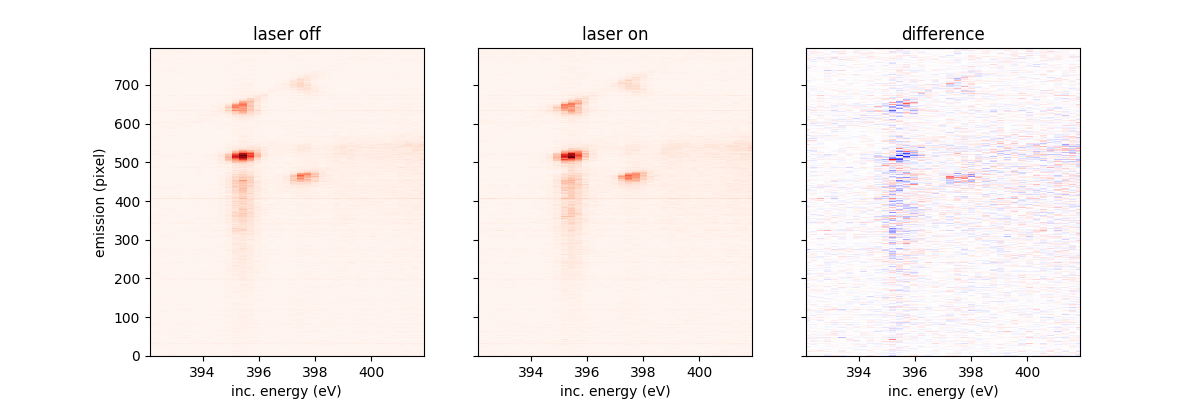

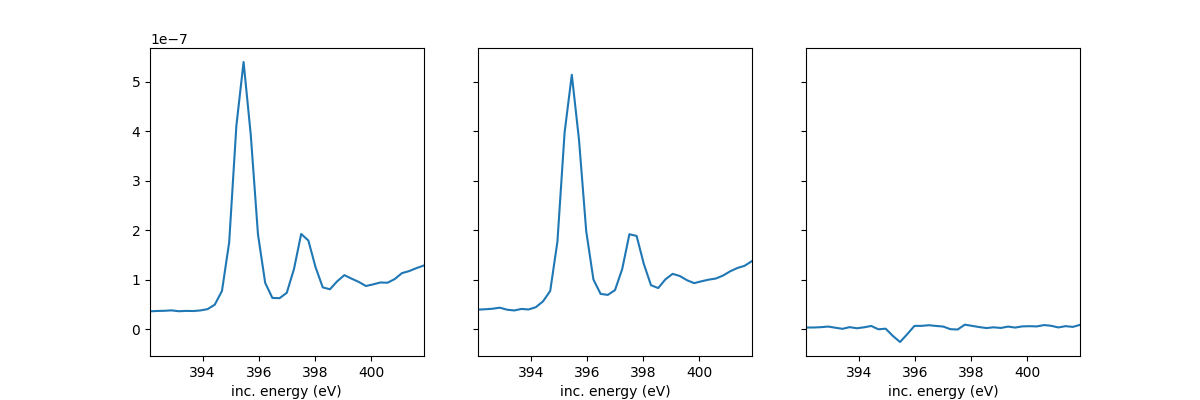

In [15]:
def integrate_fim(wf, channels, roi, bg_roi):
    """Mirror chemrixs.utils.sumchan_helper 3D path."""
    bg  = wf[..., bg_roi[0]:bg_roi[1]].mean(axis=-1)
    bgf = wf - bg[..., None]
    out = np.zeros(wf.shape[0])
    for i, c in enumerate(channels):
        out += np.nansum(np.abs(bgf[:, c-1, roi[i][0]:roi[i][1]]), axis=1)
    return out

bgrun = 106
runs=[112,113,114,116,117,120,121,122,123]

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].hist(fim0_int, bins=120); ax[0].set_title('fim0 integrated')
ax[1].hist(fim1_int, bins=120); ax[1].set_title('fim1 integrated')
ax[2].hist(I0,       bins=120); ax[2].set_title('I0 = fim0 + fim1')
for a in ax: a.set_xlabel('sum |bg-subtracted|')
plt.tight_layout(); plt.show()

print(f'I0:  median={np.median(I0):.3g}, '
      f'5%/95%={np.percentile(I0,5):.3g}/{np.percentile(I0,95):.3g}, '
      f'frac(I0<=0)={(I0<=0).mean()*100:.2f}%')

In [7]:
print(f'{"det":<6} {"ch":<4} {"peak_in_ROI":<15} {"peak_idx mean±std":<22} {"ROI":<14} {"bg_std":<10}')
for det_name, wf, det_cfg in [('fim0', fim0_wf, fim0_cfg), ('fim1', fim1_wf, fim1_cfg)]:
    for i, c in enumerate(det_cfg['channels']):
        ch = c - 1
        roi    = det_cfg['roi'][i]; bg_roi = det_cfg['bg_roi']
        bg     = wf[:, ch, bg_roi[0]:bg_roi[1]].mean(-1, keepdims=True)
        bgf    = np.abs(wf[:, ch, :] - bg)
        peak   = bgf.argmax(-1)
        in_roi = ((peak >= roi[0]) & (peak <= roi[1])).mean() * 100
        bg_std = wf[:, ch, bg_roi[0]:bg_roi[1]].std(-1).mean()
        print(f'{det_name:<6} {c:<4} {in_roi:>6.2f}%        '
              f'{peak.mean():>5.1f} ± {peak.std():>4.1f}        '
              f'[{roi[0]},{roi[1]}]    {bg_std:>8.2f}')

det    ch   peak_in_ROI     peak_idx mean±std      ROI            bg_std    
fim0   5    100.00%         71.0 ±  0.0        [65,75]      282.83
fim0   6    100.00%         71.0 ±  0.1        [65,75]      248.41
fim1   5    100.00%         65.0 ±  0.0        [59,66]      291.57
fim1   6    100.00%         64.4 ±  0.5        [59,66]      317.52
fim1   7    100.00%         64.0 ±  0.0        [59,66]      305.52


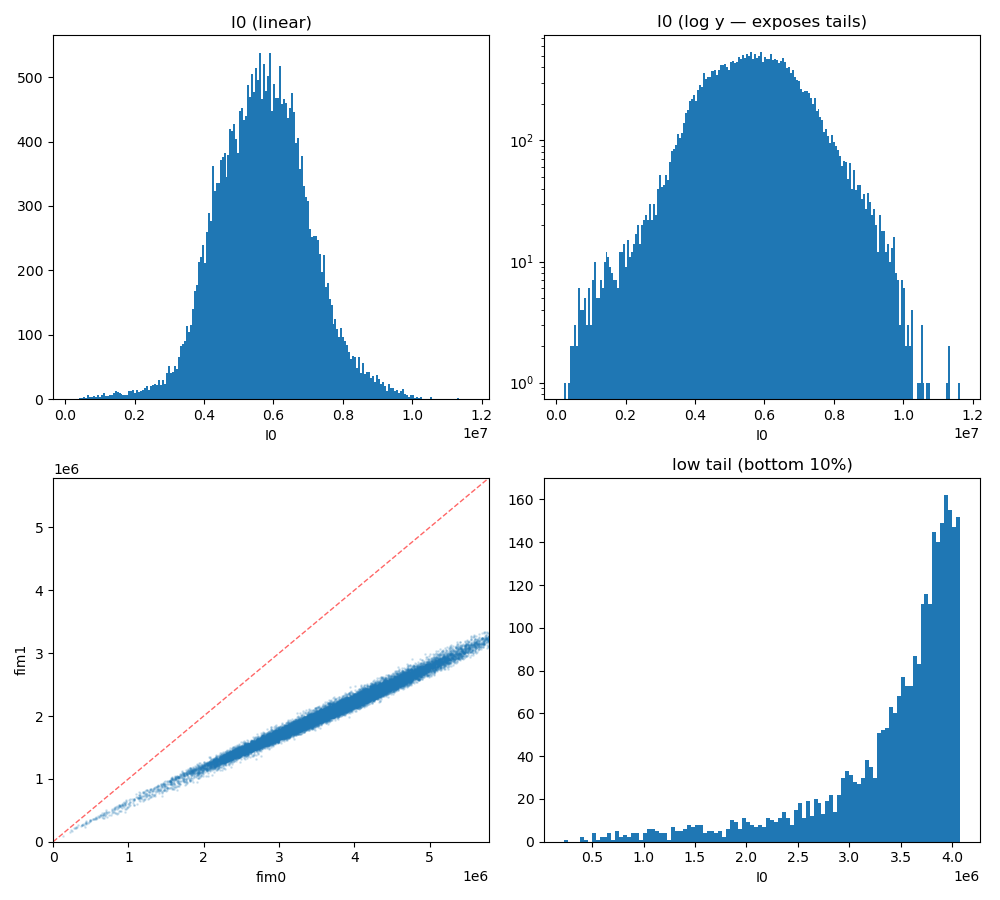

fim0: min=1.29e+05 | p0.1=5.02e+05 p1=1.51e+06 p5=2.32e+06 | med=3.65e+06 | p95=5.07e+06 p99=5.79e+06 p99.9=6.38e+06 | max=7.47e+06
       frac(<=0)=0.000%  frac(<10%·median)=0.038%
fim1: min=9.57e+04 | p0.1=3.54e+05 p1=8.96e+05 p5=1.34e+06 | med=2.05e+06 | p95=2.83e+06 p99=3.24e+06 p99.9=3.59e+06 | max=4.17e+06
       frac(<=0)=0.000%  frac(<10%·median)=0.014%
  I0: min=2.25e+05 | p0.1=8.51e+05 p1=2.41e+06 p5=3.66e+06 | med=5.7e+06 | p95=7.9e+06 p99=9.02e+06 p99.9=9.98e+06 | max=1.16e+07
       frac(<=0)=0.000%  frac(<10%·median)=0.031%


In [8]:
# === Step 2: is I0 too high / too low? ===
fig, ax = plt.subplots(2, 2, figsize=(10, 9))

ax[0,0].hist(I0, bins=200)
ax[0,0].set_title('I0 (linear)'); ax[0,0].set_xlabel('I0')

ax[0,1].hist(I0, bins=200); ax[0,1].set_yscale('log')
ax[0,1].set_title('I0 (log y — exposes tails)'); ax[0,1].set_xlabel('I0')

ax[1,0].plot(fim0_int, fim1_int, '.', ms=2, alpha=0.15)
lim = [0, np.percentile(np.r_[fim0_int, fim1_int], 99.5)]
ax[1,0].plot(lim, lim, 'r--', lw=1, alpha=0.6)
ax[1,0].set_xlim(lim); ax[1,0].set_ylim(lim)
ax[1,0].set_xlabel('fim0'); ax[1,0].set_ylabel('fim1')
# ax[1,0].set_title('fim0 vs fim1 (off-diagonal = one FIM glitched)')

avg.plot_svls2D(figsize=(12,4),savefig=True)
avg.plot_svls1D(figsize=(12,4))


In [8]:
run = runs[0]

fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
bgname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'
fyaml = '../roi_input.yml'
bgyaml = '../BGroi_input.yml'

data = SmallData(fname,fyaml)
proc = Reduced(fname,bgname,fyaml,bgyaml)
# bg = SmallData(bgname, bgyaml)

22
setting up properties
dataset prop <functools.cached_property object at 0x7f77dca7c410>
dataset prop <functools.cached_property object at 0x7f77db013090>
dataset prop <functools.cached_property object at 0x7f7bd4d1bc10>
dataset prop <functools.cached_property object at 0x7f77f1e8bbd0>
dataset prop <functools.cached_property object at 0x7f77db466590>
dataset prop <functools.cached_property object at 0x7f77db0f7fd0>
dataset prop <functools.cached_property object at 0x7f77db0f79d0>
dataset prop <functools.cached_property object at 0x7f77dca58d50>
in get scanvr: mono_fly
yes we;re in
106
setting up properties
dataset prop <functools.cached_property object at 0x7f77db0f6cd0>
dataset prop <functools.cached_property object at 0x7f77db0e1690>
dataset prop <functools.cached_property object at 0x7f77dbadb9d0>
dataset prop <functools.cached_property object at 0x7f7bd4d1b950>
dataset prop <functools.cached_property object at 0x7f77db0e2250>
dataset prop <functools.cached_property object at 0x7f


# **Uncertainty Formula for Weighted Average**:

 [
 $\sigma_{\bar{x}*{\text{w}}} = \sqrt{\frac{1}{\sum*{i=1}^{N} w_i^2} \sum_{i=1}^{N} w_i^2 \sigma_i^2}$
 ]

 Where:

 * $ \sigma_{\bar{x}_{\text{w}}} $ is the uncertainty in the weighted average.
 * $ w_i $ are the weights.
 * $ \sigma_i $ are the individual uncertainties for each measurement.

# **Uncertainty Formula for unweighted Average**:
$\sigma_{\bar{x}} = \frac{1}{\sqrt{N}} \sqrt{\sum_{i=1}^{N} \sigma_i^2}$
   

In [ ]:
proc.

array([392.1025641 , 392.30769231, 392.51282051, 392.71794872,
       392.92307692, 393.12820513, 393.33333333, 393.53846154,
       393.74358974, 393.94871795, 394.15384615, 394.35897436,
       394.56410256, 394.76923077, 394.97435897, 395.17948718,
       395.38461538, 395.58974359, 395.79487179, 396.        ,
       396.20512821, 396.41025641, 396.61538462, 396.82051282,
       397.02564103, 397.23076923, 397.43589744, 397.64102564,
       397.84615385, 398.05128205, 398.25641026, 398.46153846,
       398.66666667, 398.87179487, 399.07692308, 399.28205128,
       399.48717949, 399.69230769, 399.8974359 ])

In [ ]:
fig,ax=plt.subplots(1,1,figsize=(15,3))
ax.scatter(np.arange(len(data.integrating.axis_svls.mono))[data.integrating.axis_svls.eventcodes[:,272]==1],data.integrating.axis_svls.mono[data.integrating.axis_svls.eventcodes[:,272]==1],color='r',s=2,label='laser on')
ax.scatter(np.arange(len(data.integrating.axis_svls.mono))[data.integrating.axis_svls.eventcodes[:,273]==1],data.integrating.axis_svls.mono[data.integrating.axis_svls.eventcodes[:,273]==1],color='k',s=2,label='laser off')
ax.legend()
ax.set_xlim([0,len(data.integrating.axis_svls.mono)])
# fig.savefig('figs/mono_move_onoff.png',dpi=200,bbox_inches='tight')


In [ ]:
for run in runs:
    fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
    red = Reduced(fname,bgname,fyaml,bgyaml, save=True)



avg=avg_data(runs,proc_folder)

In [ ]:
red.data.integrating.axis_svls.mono.max()

In [ ]:
fig,ax=plt.subplots()
ax.plot(np.nansum(red.data.integrating.axis_svls.full_area,axis=0),'k',label='data')
ax.plot(np.nansum(red.bg.integrating.axis_svls.full_area,axis=0),'r',alpha=0.5,label='background')
ax.legend()
# ax.plot(np.nansum(red.proc,axis=0),'k')
# ax.plot(np.nansum(red.proc.svls,axis=0),'r')

In [ ]:
fig,ax=plt.subplots(1,1)
ax.plot(red.scanvar_on,np.sum(red.axis_svls_on_mean,1)-np.sum(red.axis_svls_off_mean,1))
ax.plot(red.scanvar_off,np.sum(red.axis_svls_off_mean,1))
# ax.set_xlim([red.scanvar_on.min(),red.scanvar_on.max()])

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(9,3),sharex=True,sharey=True)
ax[0].pcolor(avg['scanvar_on'],np.arange(avg['axis_svls_on_sum'].shape[1]),avg['axis_svls_on_sum'].T,cmap='terrain_r',vmin=0,vmax=np.nanmax(avg['axis_svls_on_sum']))
ax[1].pcolor(avg['scanvar_off'],np.arange(avg['axis_svls_off_sum'].shape[1]),avg['axis_svls_off_sum'].T,cmap='terrain_r',vmin=0,vmax=np.nanmax(avg['axis_svls_off_sum']))
ddat=np.nanmax(np.abs(avg['axis_svls_on_sum']-avg['axis_svls_off_sum']))
ax[2].pcolor(avg['scanvar_on'],np.arange(avg['axis_svls_on_sum'].shape[1]),(avg['axis_svls_on_sum']-avg['axis_svls_off_sum']).T,cmap='RdBu')
ax[0].set_xlim([avg['scanvar_off'].min(),avg['scanvar_off'].max()])

In [ ]:
emi_calib = [0.06521910251275982, 534.809958523687]
points=[[569.5,533],[573.2,589]]
mono_inc = 530

# if emi_calib == []:
#     if data.runinfo == 'mono':
emi,calib =pixel2emi(np.arange(avg['axis_svls_on_sum'].shape[1]), 
            dat=avg['axis_svls_sum'], 
            mono = avg['scanvar'], 
            calib=emi_calib, 
                points = points)
#     else:
#         print('need mono scan to calibrate using emission axis')
# else:
#     emi,calib =pixel2emi(np.arange(avg['axis_svls_sum'].shape[1]), mono=[],
#                     dat=avg['axis_svls_sum'], 
#                     calib=emi_calib) 
                    
# if data.runinfo == 'mono':
mono, E_trans_on, data_trans_on=emi2ET(avg['scanvar_on'],emi,avg['axis_svls_on_sum'],step=0.1)
mono, E_trans_off, data_trans_off=emi2ET(avg['scanvar_on'],emi,avg['axis_svls_on_sum'],step=0.1)
# else:
#     E_trans = mono_inc - emi

fig,ax=plt.subplots(1,3, sharex=True, sharey=True)
ax[0].pcolor(mono,E_trans_on, data_trans_on.T,cmap='terrain_r',vmin=-0,vmax=np.max(data_trans_on))
ax[1].pcolor(mono,E_trans_off, data_trans_off.T,cmap='terrain_r',vmin=-0,vmax=np.max(data_trans_off))
ax[2].pcolor(mono,E_trans_on, (data_trans_on-data_trans_off).T,vmin=np.min((data_trans_on-data_trans_off)),cmap='terrain_r',vmax=np.max((data_trans_on-data_trans_off)))

In [ ]:
emi_calib = [0.06521910251275982, 534.809958523687]
points=[[569.5,533],[573.2,589]]
mono_inc = 530

if emi_calib == []:
    if data.scantype == 'mono':
        emi,calib =pixel2emi(np.arange(avg['axis_svls_on_sum'].shape[1]), 
                    avg['axis_svls_on_sum'], 
                    mono = avg['scanvar_on'], 
                    calib=emi_calib, 
                    points = points)
    else:
        print('need mono scan to calibrate using emission axis')
else:
    emi,calib =pixel2emi(np.arange(avg['axis_svls_on_sum'].shape[1]), 
                    avg['axis_svls_on_sum'], 
                    calib=emi_calib) 
                    
if data.scantype == 'mono':
    mono, E_trans_on, data_trans_on=emi2ET(avg['scanvar_on'],emi,avg['axis_svls_on_sum'],step=0.1)
    mono, E_trans_off, data_trans_off=emi2ET(avg['scanvar_off'],emi,avg['axis_svls_off_sum'],step=0.1)
else:
    E_trans = mono_inc - emi

fig,ax=plt.subplots(1,3, sharex=True, sharey=True)
ax[0].pcolor(mono,E_trans_on, data_trans_on.T,cmap='terrain_r',vmin=-0,vmax=np.max(data_trans_on))
ax[1].pcolor(mono,E_trans_off, data_trans_off.T,cmap='terrain_r',vmin=-0,vmax=np.max(data_trans_off))
ax[2].pcolor(mono,E_trans_on, (data_trans_on-data_trans_off).T,vmin=np.min((data_trans_on-data_trans_off)),cmap='terrain_r',vmax=np.max((data_trans_on-data_trans_off)))

In [ ]:
fig,ax=plt.subplots(1,3)
ax[0].pcolor(avg['scanvar_on'],emi,avg['axis_svls_on_sum'].T,cmap='terrain_r',vmin=-0,vmax=np.max(avg['axis_svls_on_sum']))
ax[1].pcolor(avg['scanvar_off'],np.arange(avg['axis_svls_off_sum'].shape[1]),avg['axis_svls_off_sum'].T,cmap='terrain_r',vmin=-0,vmax=np.max(avg['axis_svls_off_sum']))
ax[2].pcolor(avg['scanvar_off'],np.arange(avg['axis_svls_off_sum'].shape[1]),(avg['axis_svls_on_sum']-avg['axis_svls_off_sum']).T,cmap='terrain_r',vmin=-0,vmax=np.max(avg['axis_svls_on_sum']-avg['axis_svls_off_sum']))



In [ ]:

fig,ax=plt.subplots(1,3)
ax[0].pcolor(red.scanvar_on,np.arange(red.axis_svls_on_mean.shape[1]),red.axis_svls_on_mean.T,cmap='terrain_r',vmin=-0,vmax=np.max(red.axis_svls_off_mean))
ax[1].pcolor(red.scanvar_off,np.arange(red.axis_svls_off_mean.shape[1]),red.axis_svls_off_mean.T,cmap='terrain_r',vmin=0,vmax=np.max(red.axis_svls_off_mean))
ax[2].pcolor(red.scanvar_on,np.arange(red.axis_svls_on_mean.shape[1]),red.axis_svls_on_mean.T-red.axis_svls_off_mean.T,cmap='terrain_r',vmin=-0,vmax=np.max(red.axis_svls_on_mean-red.axis_svls_off_mean))


In [ ]:
data.singleshot.fim_0.full_area
bg_roi=[0,50]
bg = np.mean(data.singleshot.fim_0.full_area[...,bg_roi[0]:bg_roi[1]],axis= -1)
bgf = data.singleshot.fim_0.full_area - bg[...,np.newaxis]

In [ ]:
fim_roi=[60,70]

fim_proc =subtract_bg(data.singleshot.fim_0.full_area,[0,50])
fim_wf_avs = np.nanmean(fim_proc,axis = 0)
# fim = np.sum(np.abs(fim_proc[:,:,fim_roi[0]:fim_roi[1]]),axis = (1,2))

# fim = np.nansum(fim_proc[:,:,fim_roi[0]:fim_roi[1]],axis = (1,2))

fim_sum_all = np.nansum(np.abs(fim_proc[:,:,fim_roi[0]:fim_roi[1]]),axis = 2)

In [6]:
# run=76
# fname = f'/sdf/data/lcls/ds/rix/rix100836924/scratch/h5/rix100836924_Run{run:04d}.h5'
# test = h5py.File(fname, 'r')
#run=142
#fname = f'/sdf/data/lcls/ds/rix/rix100836924/scratch/h5/rix100836924_Run{run:04d}.h5'
run=84
fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
test1 = h5py.File(fname, 'r')
test1['intg']['axis_svls'].keys()
# test1['scan']['lxt_ttc']

<KeysViewHDF5 ['c_piranha_sum_full_area', 'count', 'crix_w8_sum_base_0', 'crix_w8_sum_base_1', 'crix_w8_sum_base_2', 'crix_w8_sum_base_3', 'crix_w8_sum_base_4', 'crix_w8_sum_base_5', 'crix_w8_sum_base_6', 'crix_w8_sum_base_7', 'crix_w8_sum_base_all', 'crix_w8_sum_integral_0', 'crix_w8_sum_integral_1', 'crix_w8_sum_integral_2', 'crix_w8_sum_integral_3', 'crix_w8_sum_integral_4', 'crix_w8_sum_integral_5', 'crix_w8_sum_integral_6', 'crix_w8_sum_integral_7', 'crix_w8_sum_integral_all', 'crix_w8_sum_intensity', 'crix_w8_sum_itrigCount', 'crix_w8_sum_posX', 'crix_w8_sum_posY', 'crix_w8_sum_ptrigCount', 'det_crix_w8_sum_full_area', 'det_crix_w8_sum_wfintegrate', 'det_rix_fim0_sum_full_area', 'det_rix_fim0_sum_wfintegrate', 'det_rix_fim1_sum_full_area', 'det_rix_fim1_sum_wfintegrate', 'droplet_dense_curve_corr_corrected_image', 'droplet_dense_curve_corr_pj_ax_1_data', 'droplet_nDroplets', 'droplet_nDroplets_all', 'gmd_sum_RMS_E1', 'gmd_sum_RMS_E1_sevr', 'gmd_sum_milliJoulesPerPulse', 'gmd_sum_

In [ ]:
premirror = get_premirror_pitch(red.data.epics['MONO_premirror_pitch'][:])
hrencoder = red.data.integrating.andor_vls.mono_encoder
hr_pitch = hrencoder_to_pitch(hrencoder, red.data.yaml['mono_calib'])
hr_energy = mono_energy(hr_pitch,premirror)
hr_energy

In [ ]:
testfile = h5py.File('testsave.h5','w')
keys = vars(red)
avg = {}
for key in keys:
    avg[key] = np.zeros(testfile[key].shape)

for dat in keys:
    if 'on' in dat:
        print(dat)
        testfile.create_dataset(dat,dtype='f',data=keys[dat])
    elif 'off' in dat:
        print(dat)
        testfile.create_dataset(dat,dtype='f',data=keys[dat])


testfile.close()

In [ ]:
fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
with h5py.File(fname) as tmp:
    h5dump(tmp)


In [4]:

import dask.array as da
base_folder =  '/sdf/data/lcls/ds/rix/'
proc_folder = './proc/'
exp = 'rix101331225'
fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run0061.h5'


with h5py.File(fname,'r') as file:
    print(file['intg']['axis_svls'].keys())
    test=da.from_array(file['intg']['axis_svls']['det_crix_w8_sum_full_area'], chunks = 'auto')
    # ax.plot(np.nanmean(file['intg']['axis_svls']['curve_corr_corrected_image'],axis=0))
    # fh = h5py.File(fname, 'r')
    test_ims_thresh = file['intg/axis_svls/curve_corr_corrected_image'][:20,:][...]
    test_los_thresh = file['intg/axis_svls/curve_corr_pj_ax_1_data'][:,:][...]
plt.figure()
plt.subplot(211)
plt.plot(np.nanmean(test_los_thresh,axis =0),label = 'curve_corr_pj_ax_1_data')
plt.legend()
plt.subplot(212)
plt.plot(np.nanmean(test_ims_thresh,axis =(0,2)),label = 'lineout from curve_corr_corrected_image')
plt.xlabel('pixel')
# Plt.legend()
plt.show()

<KeysViewHDF5 ['count', 'crix_w8_sum_base_0', 'crix_w8_sum_base_1', 'crix_w8_sum_base_2', 'crix_w8_sum_base_3', 'crix_w8_sum_base_4', 'crix_w8_sum_base_5', 'crix_w8_sum_base_6', 'crix_w8_sum_base_7', 'crix_w8_sum_base_all', 'crix_w8_sum_integral_0', 'crix_w8_sum_integral_1', 'crix_w8_sum_integral_2', 'crix_w8_sum_integral_3', 'crix_w8_sum_integral_4', 'crix_w8_sum_integral_5', 'crix_w8_sum_integral_6', 'crix_w8_sum_integral_7', 'crix_w8_sum_integral_all', 'crix_w8_sum_intensity', 'crix_w8_sum_itrigCount', 'crix_w8_sum_posX', 'crix_w8_sum_posY', 'crix_w8_sum_ptrigCount', 'det_crix_w8_sum_full_area', 'det_crix_w8_sum_wfintegrate', 'det_rix_fim0_sum_full_area', 'det_rix_fim0_sum_wfintegrate', 'det_rix_fim1_sum_full_area', 'det_rix_fim1_sum_wfintegrate', 'droplet_dense_curve_corr_corrected_image', 'droplet_nDroplets', 'droplet_nDroplets_all', 'gmd_sum_RMS_E1', 'gmd_sum_RMS_E1_sevr', 'gmd_sum_milliJoulesPerPulse', 'gmd_sum_milliJoulesPerPulse_sevr', 'lightStatus_sum_laser', 'lightStatus_sum

KeyError: "Unable to synchronously open object (object 'curve_corr_corrected_image' doesn't exist)"

In [10]:
test_ims_thresh.sum()

0.0

In [10]:
run=106
fname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
with h5py.File(fname) as tmp:
    print(tmp['intg']['axis_svls']['droplet_dense_curve_corr_pj_ax_1_data'].shape)

(3983, 796)


In [9]:
run=109
fname = f'./proc/Run{run:04d}.h5'
with h5py.File(fname) as tmp:
    print(tmp['scantype'])

KeyError: "Unable to synchronously open object (object 'scantype' doesn't exist)"